In [1]:
import os

try:
    import google.colab
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/recsys-project/data'
except ImportError:
    DATA_DIR = './data'

ratings_path = os.path.join(DATA_DIR, 'ratings.dat')
movies_path = os.path.join(DATA_DIR, 'movies.dat')
users_path = os.path.join(DATA_DIR, 'users.dat')

Mounted at /content/drive


In [2]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn
# remember run this section if you haven't install packages

In [3]:
import pandas as pd

# load ratings.dat: user, item, rating, timestamp[cite: 1]
ratings = pd.read_csv(
    ratings_path, sep='::', header=None,
    names=['user_id', 'item_id', 'rating', 'timestamp'],
    engine='python'
)
print(ratings.head())
print()

# load movies.dat: item, title, genres[cite: 1]
movies = pd.read_csv(
    movies_path, sep='::', header=None,
    names=['item_id', 'title', 'genres'],
    engine='python', encoding='latin-1'
)
print(movies.head())
print()

# load users.dat: user, gender, age, occupation, zip[cite: 1]
users = pd.read_csv(
    users_path, sep='::', header=None,
    names=['user_id', 'gender', 'age', 'occupation', 'zip_code'],
    engine='python'
)
print(users.head())

print()
print(f"Loaded {len(ratings)} ratings, {len(movies)} movies, {len(users)} users.")

   user_id  item_id  rating  timestamp
0        1     1193       5  978300760
1        1      661       3  978302109
2        1      914       3  978301968
3        1     3408       4  978300275
4        1     2355       5  978824291

   item_id                               title                        genres
0        1                    Toy Story (1995)   Animation|Children's|Comedy
1        2                      Jumanji (1995)  Adventure|Children's|Fantasy
2        3             Grumpier Old Men (1995)                Comedy|Romance
3        4            Waiting to Exhale (1995)                  Comedy|Drama
4        5  Father of the Bride Part II (1995)                        Comedy

   user_id gender  age  occupation zip_code
0        1      F    1          10    48067
1        2      M   56          16    70072
2        3      M   25          15    55117
3        4      M   45           7    02460
4        5      M   25          20    55455

Loaded 1000209 ratings, 3883 movies, 

# PART 1


## Analyze the data characterization


In [9]:
# basic information got user, items, ratings and matrix density
n_users = ratings['user_id'].nunique()
n_items = ratings['item_id'].nunique()
n_interactions = len(ratings)
density = n_interactions / (n_users * n_items)


print("Dataset Characterization Summary:")
print(f"- Total Users: {n_users}")
print(f"- Total Items (Movies): {n_items}")
print(f"- Total Interactions (Ratings): {n_interactions}")
print(f"- Matrix Density: {density:.6f} ({density * 100:.4f}%)")

Dataset Characterization Summary:
- Total Users: 6040
- Total Items (Movies): 3706
- Total Interactions (Ratings): 1000209
- Matrix Density: 0.044684 (4.4684%)


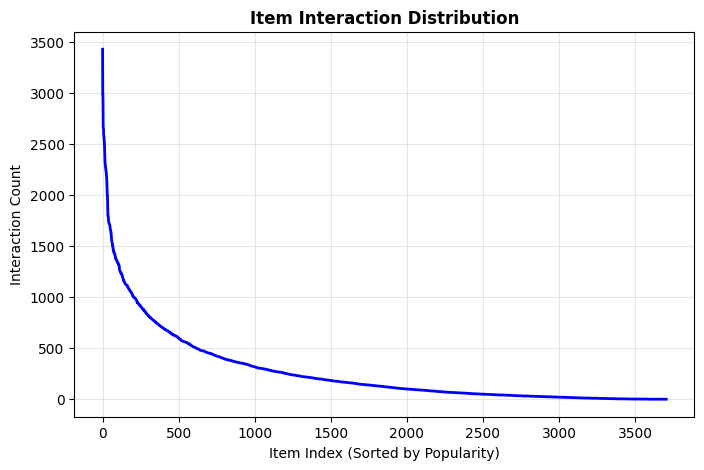

In [ ]:
# Item interaction distribution
import numpy as np
import matplotlib.pyplot as plt


item_counts = ratings['item_id'].value_counts().values
item_counts_sorted = np.sort(item_counts)[::-1]

plt.figure(figsize=(8, 5))
plt.plot(item_counts_sorted, color='b', linewidth=2)
plt.title('Item Interaction Distribution',
          fontsize=12, fontweight='bold')
plt.xlabel('Item Index (Sorted by Popularity)')
plt.ylabel('Interaction Count')
plt.grid(alpha=0.3)

# plt.savefig('/content/drive/MyDrive/recsys-project/figure/Item Interaction Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

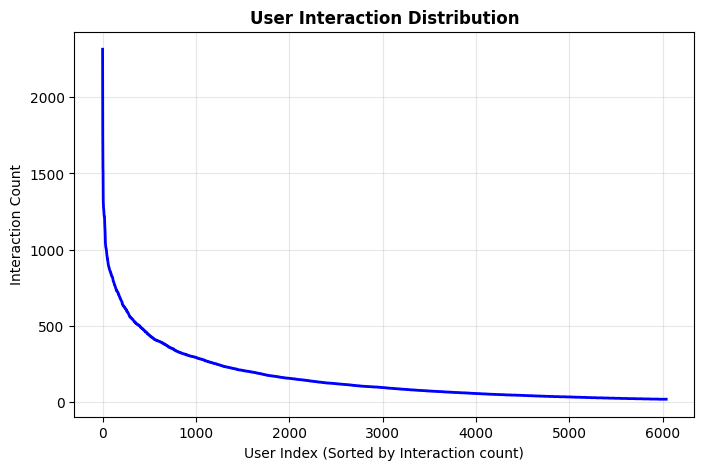

In [ ]:
# User Interaction Distribution
user_counts = ratings['user_id'].value_counts().values
user_counts_sorted = np.sort(user_counts)[::-1]


plt.figure(figsize=(8, 5))
plt.plot(user_counts, color='b', linewidth=2)

plt.title('User Interaction Distribution',
          fontsize=12, fontweight='bold')
plt.xlabel('User Index (Sorted by Interaction count)')
plt.ylabel('Interaction Count')
plt.grid(alpha=0.3)

# plt.savefig('/content/drive/MyDrive/recsys-project/figure/User Interaction Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_3325/1061845512.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


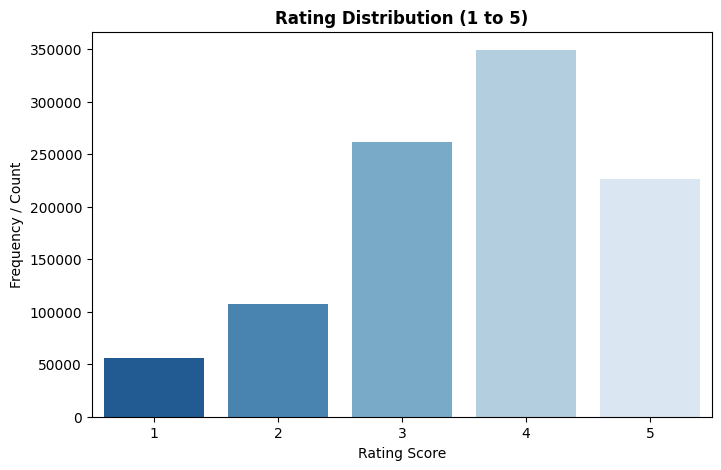

In [ ]:
# Ratings Distribution
import seaborn as sns

plt.figure(figsize=(8, 5))
ax = plt.gca()

sns.countplot(
    x='rating',
    data=ratings,
    ax=ax,
    palette='Blues_r'
)

ax.set_title('Rating Distribution (1 to 5)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Rating Score')
ax.set_ylabel('Frequency / Count')

# plt.savefig('/content/drive/MyDrive/recsys-project/figure/Rating Distribution (1 to 5).png', dpi=300, bbox_inches='tight')
plt.show()

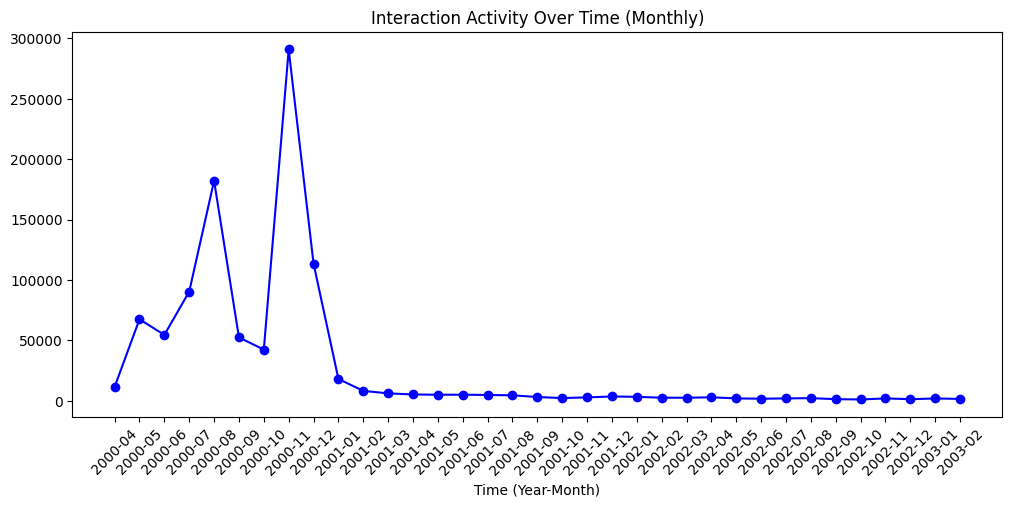

In [ ]:
# Time Span & Activity Distribution
ratings['datetime'] = pd.to_datetime(ratings['timestamp'], unit='s')
ratings['date'] = ratings['datetime'].dt.to_period('M').astype(str)

activity_over_time = ratings.groupby('date').size()

plt.figure(figsize=(12, 5))
plt.xticks(rotation=45)
ax = plt.gca()

ax.plot(
    activity_over_time.index,
    activity_over_time.values,
    marker='o',
    color='b',
    linestyle='-'
)

ax.set_title('Interaction Activity Over Time (Monthly)')
ax.set_xlabel('Time (Year-Month)')

plt.xticks(rotation=45)

# plt.savefig('/content/drive/MyDrive/recsys-project/figure/Interaction Activity Over Time (Monthly).png', dpi=300, bbox_inches='tight')
plt.show()

## Train/validation/test split
To decide the split method, we need to check if the popularity has strong correlation with time. Here we check if the top-k most popular movies changed over time.

In [17]:
ratings_sorted = ratings.sort_values('timestamp')

mid = len(ratings_sorted) // 2

early_data = ratings_sorted.iloc[:mid]
late_data = ratings_sorted.iloc[mid:]

K = 10

early_top_k = set(
    early_data['item_id'].value_counts().head(K).index
)

late_top_k = set(
    late_data['item_id'].value_counts().head(K).index
)

overlap = len(early_top_k & late_top_k)
overlap_ratio = overlap / K

print("Early Top 10:", early_top_k)
print("Late Top 10:", late_top_k)
print(f"Common items: {overlap}")
print(f"Top-10 overlap ratio: {overlap_ratio:.2%}")

Early Top 10: {608, 260, 2858, 2571, 1196, 2762, 2028, 593, 1270, 1210}
Late Top 10: {480, 260, 2858, 1196, 589, 2028, 1580, 110, 593, 1210}
Common items: 6
Top-10 overlap ratio: 60.00%


Thus, we decide to use the  recent window for most popular baseline, and split the data by time.

In [18]:
ratings = ratings.sort_values('timestamp')

train_ratio, val_ratio = 0.7, 0.15
n = len(ratings)
train_end = int(n * train_ratio)
val_end = int(n * (train_ratio + val_ratio))

train_set = ratings.iloc[:train_end]
val_set = ratings.iloc[train_end:val_end]
test_set = ratings.iloc[val_end:]

print(f"Train size: {len(train_set)}, Val size: {len(val_set)}, Test size: {len(test_set)}")

Train size: 700146, Val size: 150031, Test size: 150032


In [27]:
datasets = {
    'Training': train_set,
    'Validation': val_set,
    'Test': test_set
}

for name, df in datasets.items():
    start_time = pd.to_datetime(
        df['timestamp'].min(), unit='s', utc=True
    )

    end_time = pd.to_datetime(
        df['timestamp'].max(), unit='s', utc=True
    )

    print(f"{name} set:")
    print(f"  Start: {start_time}")
    print(f"  End:   {end_time}")
    print(f"  Interactions: {len(df)}")
    print()

Training set:
  Start: 2000-04-25 23:05:32+00:00
  End:   2000-11-22 03:06:26+00:00
  Interactions: 700146

Validation set:
  Start: 2000-11-22 03:06:26+00:00
  End:   2000-12-10 04:20:42+00:00
  Interactions: 150031

Test set:
  Start: 2000-12-10 04:20:54+00:00
  End:   2003-02-28 17:49:50+00:00
  Interactions: 150032



## Metrics

In [35]:
def evaluate_model(recommend_func, relevant_items, catalogue, k=10):

  precisions = []
  recalls = []
  ndcg_scores = []
  recommended_items = set()

  for user_id, relevant in relevant_items.items():

    recommendations = recommend_func(user_id, top_k=k)
    recommendations = recommendations[:k]

    recommended_items.update(recommendations)

    hits = len(set(recommendations) & relevant)

    # Precision@K
    precisions.append(hits / k)

    # Recall@K
    recalls.append(hits / len(relevant))

    # NDCG@K
    dcg = sum(
          1 / np.log2(rank + 1)
          for rank, item_id in enumerate(recommendations, start=1)
          if item_id in relevant)

    ideal_hits = min(len(relevant), k)

    idcg = sum(
          1 / np.log2(rank + 1)
          for rank in range(1, ideal_hits + 1))

    ndcg_scores.append(dcg / idcg if idcg > 0 else 0.0)

  # Catalogue Coverage
  coverage = len(recommended_items) / len(catalogue)

  return {
      'Precision@10': np.mean(precisions),
      'Recall@10': np.mean(recalls),
      'NDCG@10': np.mean(ndcg_scores),
      'Catalogue Coverage': coverage}

## Baselines - setup

In [36]:
item_user_matrix = train_set.pivot_table(
    index='item_id',
    columns='user_id',
    values='rating',
    fill_value=0
)

item_ids = item_user_matrix.index.to_numpy()
catalogue = set(item_ids)

# Relevant items in validation and test sets
relevant_val = (
    val_set[val_set['rating'] >= 4]
    .groupby('user_id')['item_id']
    .apply(set)
    .to_dict()
)

relevant_test = (
    test_set[test_set['rating'] >= 4]
    .groupby('user_id')['item_id']
    .apply(set)
    .to_dict()
)

user_seen_items = {
    user_id: set(group['item_id'])
    for user_id, group in train_set.groupby('user_id')
}

user_ratings = {
    user_id: dict(zip(group['item_id'], group['rating']))
    for user_id, group in train_set.groupby('user_id')
}

## Baselines - Item Based kNN

In [37]:
from sklearn.neighbors import NearestNeighbors

def item_based_knn(n_neighbors, similarity_measure):

  n = min(n_neighbors + 1, len(item_ids))

  knn_model = NearestNeighbors(
        metric=similarity_measure,
        algorithm='brute',
        n_neighbors=n
  )

  knn_model.fit(item_user_matrix)

  distances, indices = knn_model.kneighbors(item_user_matrix)

  if similarity_measure in ['cosine', 'correlation']:
    similarities = 1 - distances

  elif similarity_measure == 'euclidean':
    similarities = 1 / (1 + distances)

  item_neighbors = {}
  for i, item_id in enumerate(item_ids):
    neighbors = []

    for j, sim in zip(indices[i], similarities[i]):
      neighbor_id = item_ids[j]

      if neighbor_id != item_id:
        neighbors.append((neighbor_id, sim))

    item_neighbors[item_id] = neighbors

  return item_neighbors


In [38]:
def recommend_item_based_knn(user_id, item_neighbors, top_k):

  seen_items = user_seen_items.get(user_id, set())
  ratings = user_ratings.get(user_id, {})

  scores = {}

  for item_id, rating in ratings.items():
    if rating < 4:
      continue

    for neighbor_id, similarity in item_neighbors.get(item_id, []):
      if neighbor_id in seen_items:
        continue

      scores[neighbor_id] = (
        scores.get(neighbor_id, 0)
        + similarity * rating)

  ranked_items = sorted(
    scores.items(),
    key=lambda x: x[1],
    reverse=True)

  return [item for item, score in ranked_items[:top_k]]


In [39]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd

k_values = [1, 5, 50, 150, 200]
similarity_measures = ['cosine', 'euclidean', 'correlation']

results = []

for k in k_values:
  for sm in similarity_measures:
    item_neighbors = item_based_knn(k, sm)

    def recommend_func(user_id, top_k=10):
      return recommend_item_based_knn(user_id, item_neighbors, top_k)

    metrics = evaluate_model(
            recommend_func,
            relevant_val,
            catalogue)

    results.append({
            'n_neighbors': k,
            'similarity measure': sm,
            **metrics})

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

display(results_df.round(4))

,n_neighbors,similarity measure,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,1,cosine,0.0407,0.0164,0.0481,0.1431
1,1,euclidean,0.0064,0.0022,0.0060,0.2684
2,1,correlation,0.0343,0.0117,0.0387,0.1621
3,5,cosine,0.0531,0.0183,0.0579,0.1159
4,5,euclidean,0.0052,0.0018,0.0053,0.2772
5,5,correlation,0.0414,0.0140,0.0453,0.1495
6,50,cosine,0.0578,0.0181,0.0633,0.0735
7,50,euclidean,0.0029,0.0008,0.0032,0.1905
8,50,correlation,0.0404,0.0143,0.0444,0.1497
9,150,cosine,0.0600,0.0182,0.0659,0.0606


## Baseline - Most Popular

In [43]:
def recommend_most_popular(user_id, popularity, top_k=10):

  seen_items = user_seen_items.get(user_id, set())

  recommendations = [
    item_id for item_id in popularity.index
    if item_id not in seen_items
    ]

  return recommendations[:top_k]

In [46]:
# Tune the most popular model with different popularity variants
popularity_variants = ['all_ratings', 'positive_ratings']
results = []

for variant in popularity_variants:

  if variant == 'all_ratings':
    item_popularity = train_set['item_id'].value_counts()

  elif variant == 'positive_ratings':
    item_popularity = (
      train_set[train_set['rating'] >= 4]['item_id'].value_counts())

  popular_items = item_popularity.index.tolist()

  def recommend_func(user_id, top_k=10, popularity=item_popularity):
    return recommend_most_popular(user_id, popularity, top_k)

  metrics = evaluate_model(
        recommend_func,
        relevant_val,
        catalogue
    )

  results.append({
    'Popularity variant': variant,
    **metrics})

results_df = pd.DataFrame(results)

popular_results_df = pd.DataFrame(results)

display(popular_results_df.round(4))


,Popularity variant,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,all_ratings,0.2753,0.0608,0.2957,0.0325
1,positive_ratings,0.2781,0.0618,0.2982,0.0289


Now we decide to choose k=150, measure='cosine' for item based kNN, and positive rating for most popular. Next we will examine the model with test set.

In [47]:
# Set up dataset
final_neighbors = item_based_knn(
  n_neighbors=150,
  similarity_measure='cosine'
)

def knn_final(user_id, top_k=10):
  return recommend_item_based_knn(user_id, final_neighbors, top_k)

positive_popularity = (
  train_set[train_set['rating'] >= 4]['item_id'].value_counts()
)

def popular_final(user_id, top_k=10):
  return recommend_most_popular(user_id, positive_popularity, top_k)


final_models = {
  'Item-based KNN (Cosine, k=150)': knn_final,
  'Most Popular (Positive ratings)': popular_final
}


In [48]:
test_results = []

for model_name, recommend_func in final_models.items():

  metrics = evaluate_model(
    recommend_func,
    relevant_test,
    catalogue
    )

  test_results.append({
    'Model': model_name,
    **metrics
  })


test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Model,Precision@10,Recall@10,NDCG@10,Catalogue Coverage
0,"Item-based KNN (Cosine, k=150)",0.1113,0.0309,0.1234,0.0718
1,Most Popular (Positive ratings),0.2199,0.0518,0.2332,0.0333
